# Uçtan Uca Yapay Zeka Projesi: Veriden Tahmine
## Öğrenci Başarısı Erken Uyarı Sistemi (UCI Student Performance)

**Araçlar:** Python, Pandas, NumPy, Matplotlib, Seaborn, scikit-learn · **Ortam:** Google Colab / Jupyter

Bu çalışma **gerçek bir veri seti** üzerinde, basit bir karar ağacının ötesine geçer: çoklu model karşılaştırması, tekrarlı çapraz doğrulama, hiperparametre ayarı, iki senaryo (notlu / notsuz), permütasyon önemi, öğrenme eğrisi, eşik analizi ve adalet (fairness) kontrolü içerir.

> **Colab:** `git clone https://github.com/b4tukk/python-ogrenci-basari` sonra `%cd python-ogrenci-basari`; ya da `data/student-mat.csv` dosyasını yükleyin.

## Aşama 1 — Problem Tanımı
- **Problem:** Bir lise öğrencisinin demografik, sosyal ve okul bilgilerinden dönem sonunda matematik dersini **geçip geçmeyeceğini** (`G3 ≥ 10`) tahmin et.
- **Hedef:** `gecti` (1 = geçti, 0 = kaldı) → **ikili sınıflandırma**.
- **İki senaryo:**
  - **A — Erken uyarı:** Dönem başında bilinen bilgiler (ara not **yok**). Gerçekçi ve zor.
  - **B — Ara notlu:** `G1`, `G2` dönem içi notları da kullanılır. Kolay, ama geç uyarı.
- **Kime fayda:** Rehber öğretmen, risk altındaki öğrenciye *dönem başında* destek verebilir. Bu bir karar aracı değil, **öncelik belirleme** aracıdır.
- **Başarı ölçütü:** "Kalacak" öğrenciyi kaçırmak (yanlış negatif) pahalı olduğundan, **kalan sınıfı için recall** ve F1 ana metriklerdir; accuracy tek başına yeterli değildir.

## Aşama 2 — Veri ve Temizleme
**Kaynak:** Cortez & Silva (2008), *UCI Machine Learning Repository — Student Performance*, 395 öğrenci (Portekiz, matematik dersi). Lisans: CC BY 4.0.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, os
sns.set_theme(style="whitegrid"); os.makedirs("figures", exist_ok=True); os.makedirs("models", exist_ok=True)
METRICS = {}
df = pd.read_csv("data/student-mat.csv", sep=";")
print(df.shape); print("Eksik değer:", int(df.isnull().sum().sum()), "| Yinelenen satır:", int(df.duplicated().sum()))
df.head(3)

(395, 33)
Eksik değer: 0 | Yinelenen satır: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10


### Veri sözlüğü (özet)
| Grup | Sütunlar | Tip |
|---|---|---|
| Demografik | school, sex, age, address, famsize, Pstatus | kategorik/sayısal |
| Aile | Medu, Fedu (0–4), Mjob, Fjob, guardian, famrel (1–5), famsup | sıralı/kategorik |
| Okul/Çalışma | studytime (1–4), failures (0–3), schoolsup, paid, activities, higher, absences | sayısal/kategorik |
| Sosyal | goout, freetime, Dalc, Walc (1–5), romantic, internet, health | sıralı |
| Ara notlar | G1, G2 (0–20) | sayısal |
| **Hedef** | **G3** (0–20) → `gecti = G3 ≥ 10` | |

**Temizleme kararları:** Eksik değer yok; ancak `G3 = 0` olan öğrenciler (sınava hiç girmemiş olabilir) gerçek "kalma"dan farklı olabilir; veri bu haliyle bırakıldı ve sınırlılık olarak raporlandı.

In [2]:
df["gecti"] = (df["G3"] >= 10).astype(int)
print("G3=0 olan öğrenci:", int((df.G3 == 0).sum()))
print(df.gecti.value_counts(normalize=True).round(3).rename({1: "geçti", 0: "kaldı"}))
METRICS["n"] = len(df); METRICS["gecme_orani"] = float(df.gecti.mean())

G3=0 olan öğrenci: 38
gecti
geçti    0.671
kaldı    0.329
Name: proportion, dtype: float64


## Aşama 3 — Keşifçi Veri Analizi (EDA)

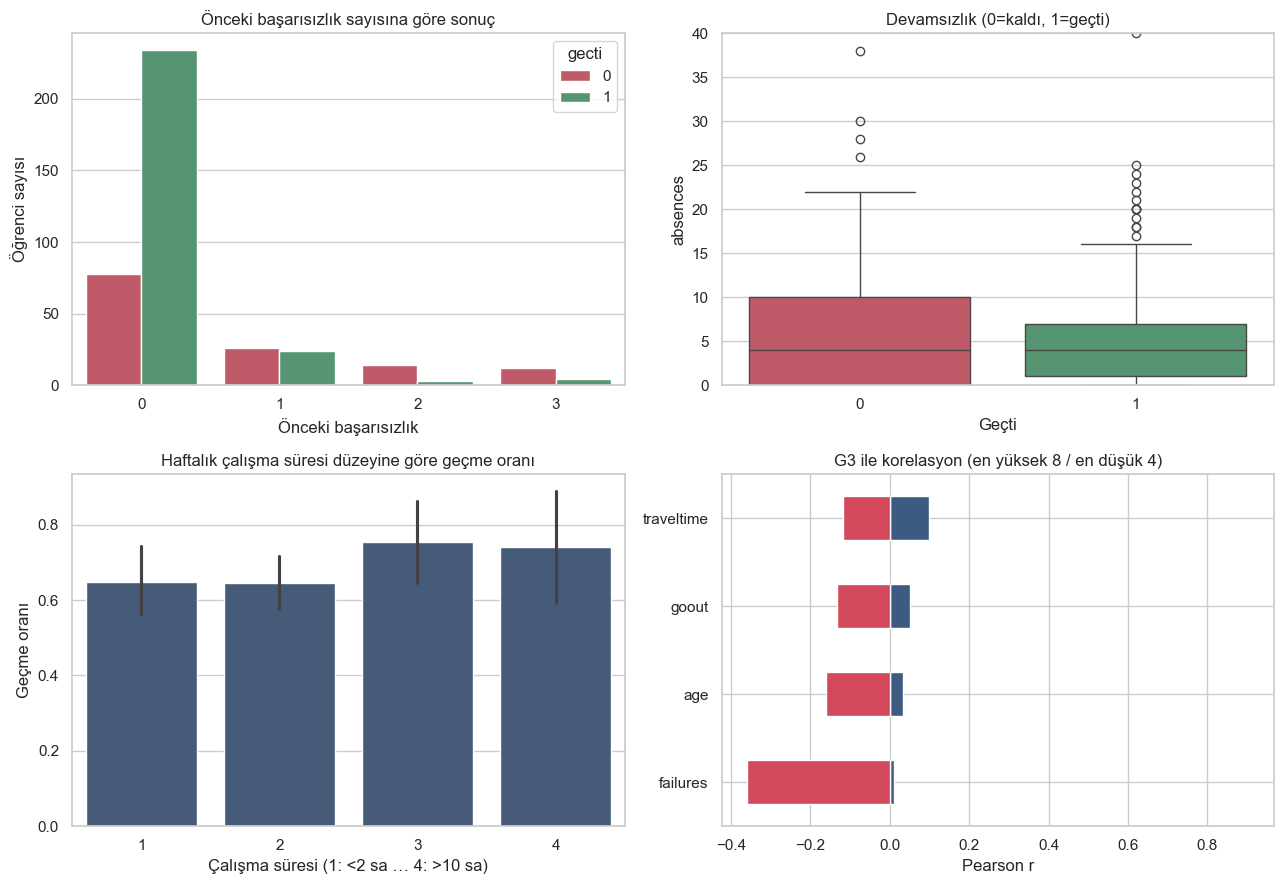

       studytime  failures  absences    age  Medu  Walc
gecti                                                  
0           1.95      0.69      6.76  17.02  2.57  2.35
1           2.08      0.16      5.19  16.54  2.84  2.26

Hedefle en ilişkili (G1, G2 hariç):
 failures    0.360
Medu        0.217
age         0.162
Fedu        0.152
goout       0.133
Name: G3, dtype: float64


In [3]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
sns.countplot(data=df, x="failures", hue="gecti", ax=ax[0, 0], palette=["#d1495b", "#4c9f70"]); ax[0, 0].set_title("Önceki başarısızlık sayısına göre sonuç"); ax[0, 0].set_xlabel("Önceki başarısızlık"); ax[0, 0].set_ylabel("Öğrenci sayısı")
sns.boxplot(data=df, x="gecti", y="absences", ax=ax[0, 1], palette=["#d1495b", "#4c9f70"]); ax[0, 1].set_ylim(0, 40); ax[0, 1].set_title("Devamsızlık (0=kaldı, 1=geçti)"); ax[0, 1].set_xlabel("Geçti")
sns.barplot(data=df, x="studytime", y="gecti", ax=ax[1, 0], color="#3d5a80"); ax[1, 0].set_title("Haftalık çalışma süresi düzeyine göre geçme oranı"); ax[1, 0].set_xlabel("Çalışma süresi (1: <2 sa … 4: >10 sa)"); ax[1, 0].set_ylabel("Geçme oranı")
num = df.select_dtypes("number").drop(columns=["gecti"]).corr()["G3"].drop(["G3"]).sort_values()
num.tail(8).plot.barh(ax=ax[1, 1], color="#3d5a80"); num.head(4).plot.barh(ax=ax[1, 1], color="#d1495b"); ax[1, 1].set_title("G3 ile korelasyon (en yüksek 8 / en düşük 4)"); ax[1, 1].set_xlabel("Pearson r")
plt.tight_layout(); plt.savefig("figures/eda.png", dpi=150); plt.show()
print(df.groupby("gecti")[["studytime", "failures", "absences", "age", "Medu", "Walc"]].mean().round(2))
print("\nHedefle en ilişkili (G1, G2 hariç):\n", num.drop(["G1", "G2"]).abs().sort_values(ascending=False).head(5).round(3))

### Keşif bulguları
1. **`failures` (önceki başarısızlık)** en güçlü sosyal/okul göstergesi: başarısızlığı olanlarda geçme oranı belirgin şekilde düşük.
2. `G1` ve `G2` ile `G3` arasında çok yüksek korelasyon var → **Senaryo B'de modelin neredeyse tamamı ara notlara dayanacak** (bu bir "sızıntıya yakın" durumdur; bu yüzden iki senaryo ayrı raporlanıyor).
3. Çalışma süresi arttıkça geçme oranı artıyor ama fark yumuşak; tek başına belirleyici değil.
4. Devamsızlık dağılımı çok çarpık (birkaç büyük değer). Ağaç tabanlı modeller bundan etkilenmez; lineer modellerde ölçekleme gerekir.
5. Sınıflar dengesiz (≈ %67 geçti); bu yüzden "hep geçer de" taban çizgisi ≈ %67 doğruluk verir ve **accuracy yanıltıcıdır**.

## Aşama 4 — Özellik Mühendisliği ve Veri Bölme
Eklenen özellikler: `alkol_ort` (Dalc ve Walc ortalaması), `ebeveyn_egitim` (Medu+Fedu), `sosyal_yuk` (goout+freetime), `devamsiz_log` (log1p(absences)).
Bölme: **%80 eğitim / %20 test, `stratify=y`**. Test seti hiperparametre seçiminde kullanılmaz.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone

def ozellik_ekle(d):
    d = d.copy()
    d["alkol_ort"] = (d.Dalc + d.Walc) / 2
    d["ebeveyn_egitim"] = d.Medu + d.Fedu
    d["sosyal_yuk"] = d.goout + d.freetime
    d["devamsiz_log"] = np.log1p(d.absences)
    return d

d2 = ozellik_ekle(df)
y = d2["gecti"]
ARA_NOT = ["G1", "G2"]
X_full = d2.drop(columns=["G3", "gecti"])
cat_cols = X_full.select_dtypes("object").columns.tolist()
def make_pre(cols):
    cats = [c for c in cols if c in cat_cols]; nums = [c for c in cols if c not in cat_cols]
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cats), ("num", StandardScaler(), nums)])

idx_tr, idx_te = train_test_split(np.arange(len(d2)), test_size=0.2, random_state=42, stratify=y)
print("Eğitim:", len(idx_tr), "Test:", len(idx_te), "| test geçme oranı:", round(y.iloc[idx_te].mean(), 3))

Eğitim: 316 Test: 79 | test geçme oranı: 0.671


## Aşama 5 — Model Karşılaştırma (Senaryo A: ara not yok)
5 model, **5×3 tekrarlı katmanlı çapraz doğrulama** (yalnızca eğitim verisinde). Ana ölçüt: F1 (kalan sınıfı pozitif alınarak) ve ROC-AUC.

In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

y_kal = 1 - y   # pozitif sınıf = KALAN öğrenci (erken uyarıda yakalamak istediğimiz)
colsA = [c for c in X_full.columns if c not in ARA_NOT]
colsB = list(X_full.columns)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
def modeller():
    return {
        "Taban çizgisi (en sık sınıf)": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
        "Karar Ağacı (derinlik 4)": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42),
        "KNN (k=15)": KNeighborsClassifier(n_neighbors=15),
        "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", min_samples_leaf=3, random_state=42, n_jobs=-1),
        "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    }
def cv_tablo(cols):
    rows = []
    for ad, mdl in modeller().items():
        pipe = Pipeline([("pre", make_pre(cols)), ("m", mdl)])
        s = cross_validate(pipe, X_full.iloc[idx_tr][cols], y_kal.iloc[idx_tr], cv=cv, scoring=["accuracy", "recall", "precision", "f1", "roc_auc"], n_jobs=-1)
        rows.append({"Model": ad, **{k: (s[f"test_{k}"].mean(), s[f"test_{k}"].std()) for k in ["accuracy", "recall", "precision", "f1", "roc_auc"]}})
    t = pd.DataFrame(rows).set_index("Model")
    return t
tabA = cv_tablo(colsA)
show = tabA.map(lambda v: f"{v[0]:.3f} ± {v[1]:.3f}"); display(show)
METRICS["cv_A"] = {k: {c_: round(v[0], 4) for c_, v in r.items()} for k, r in tabA.iterrows()}

,accuracy,recall,precision,f1,roc_auc
Model,,,,,
Taban çizgisi (en sık sınıf),0.671 ± 0.006,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
Logistic Regression,0.691 ± 0.047,0.603 ± 0.110,0.527 ± 0.066,0.559 ± 0.079,0.712 ± 0.050
Karar Ağacı (derinlik 4),0.650 ± 0.052,0.410 ± 0.095,0.476 ± 0.081,0.432 ± 0.068,0.589 ± 0.053
KNN (k=15),0.708 ± 0.025,0.154 ± 0.056,0.782 ± 0.212,0.254 ± 0.086,0.639 ± 0.039
Random Forest,0.710 ± 0.033,0.407 ± 0.055,0.595 ± 0.086,0.479 ± 0.052,0.693 ± 0.051
Gradient Boosting,0.704 ± 0.044,0.398 ± 0.096,0.579 ± 0.114,0.465 ± 0.094,0.673 ± 0.061


## Aşama 6 — Hiperparametre Ayarı ve Test Değerlendirmesi (Senaryo A)
En umut verici iki aile (Logistic Regression, Random Forest) `GridSearchCV` ile ayarlanır (ölçüt: F1). Seçilen model **ilk kez** test setinde değerlendirilir.

In [6]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
skf = StratifiedKFold(5, shuffle=True, random_state=42)
Xtr, Xte = X_full.iloc[idx_tr][colsA], X_full.iloc[idx_te][colsA]; ytr, yte = y_kal.iloc[idx_tr], y_kal.iloc[idx_te]
adaylar = {
    "Logistic Regression": (LogisticRegression(max_iter=3000, class_weight="balanced"), {"m__C": [0.01, 0.03, 0.1, 0.3, 1]}),
    "Random Forest": (RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1), {"m__n_estimators": [200, 400], "m__max_depth": [3, 5, 8], "m__min_samples_leaf": [3, 6]}),
}
tuned = {}
for ad, (mdl, grid) in adaylar.items():
    gs = GridSearchCV(Pipeline([("pre", make_pre(colsA)), ("m", mdl)]), grid, cv=skf, scoring="f1", n_jobs=-1).fit(Xtr, ytr)
    tuned[ad] = gs.best_estimator_; print(f"{ad}: en iyi {gs.best_params_} | CV F1 = {gs.best_score_:.3f}")
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve, precision_recall_curve, f1_score, recall_score, precision_score, accuracy_score
sonuc = {}
for ad, mdl in tuned.items():
    p = mdl.predict(Xte); pr = mdl.predict_proba(Xte)[:, 1]
    sonuc[ad] = dict(accuracy=accuracy_score(yte, p), precision=precision_score(yte, p), recall=recall_score(yte, p), f1=f1_score(yte, p), auc=roc_auc_score(yte, pr), proba=pr, pred=p)
display(pd.DataFrame({k: {m_: round(v, 3) for m_, v in r.items() if m_ not in ("proba", "pred")} for k, r in sonuc.items()}).T)
taban = max(1 - yte.mean(), yte.mean()); print("Test taban çizgisi doğruluğu:", round(taban, 3))
METRICS["test_A"] = {k: {m_: round(float(v), 4) for m_, v in r.items() if m_ not in ("proba", "pred")} for k, r in sonuc.items()}; METRICS["taban_dogruluk"] = float(taban)

Logistic Regression: en iyi {'m__C': 0.1} | CV F1 = 0.589


Random Forest: en iyi {'m__max_depth': 5, 'm__min_samples_leaf': 3, 'm__n_estimators': 200} | CV F1 = 0.524


,accuracy,precision,recall,f1,auc
Logistic Regression,0.658,0.478,0.423,0.449,0.623
Random Forest,0.671,0.500,0.385,0.435,0.633


Test taban çizgisi doğruluğu: 0.671


Seçilen model: Logistic Regression


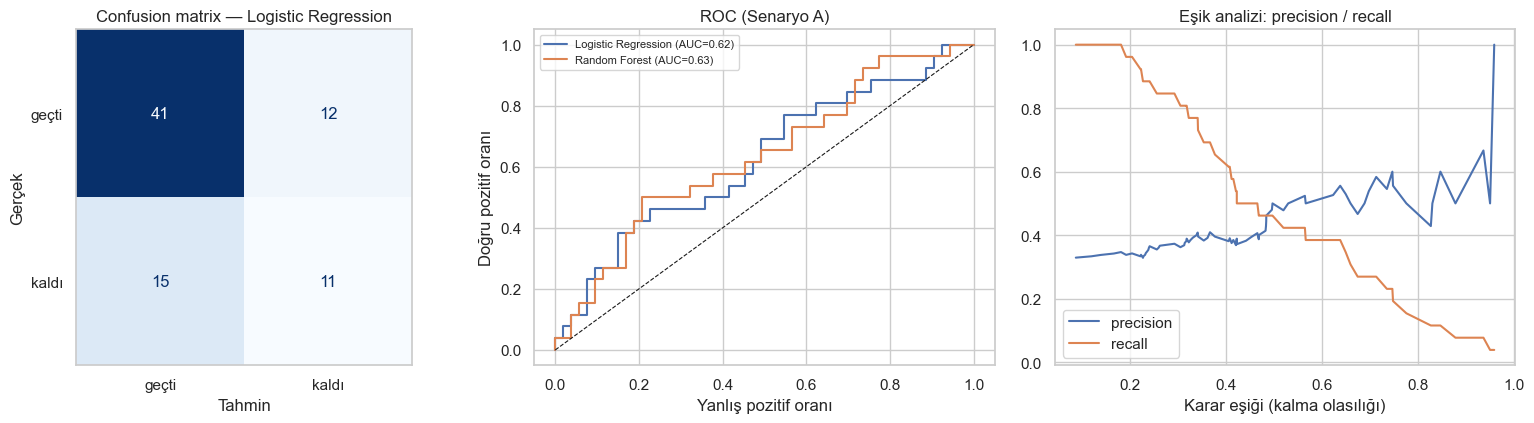

              precision    recall  f1-score   support

       geçti       0.73      0.77      0.75        53
       kaldı       0.48      0.42      0.45        26

    accuracy                           0.66        79
   macro avg       0.61      0.60      0.60        79
weighted avg       0.65      0.66      0.65        79



In [7]:
en_iyi_ad = max(sonuc, key=lambda k: sonuc[k]["f1"]); en_iyi = tuned[en_iyi_ad]; print("Seçilen model:", en_iyi_ad)
METRICS["secilen_A"] = en_iyi_ad
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
ConfusionMatrixDisplay(confusion_matrix(yte, sonuc[en_iyi_ad]["pred"]), display_labels=["geçti", "kaldı"]).plot(ax=ax[0], cmap="Blues", colorbar=False); ax[0].set_title(f"Confusion matrix — {en_iyi_ad}"); ax[0].grid(False); ax[0].set_xlabel("Tahmin"); ax[0].set_ylabel("Gerçek")
for ad, r in sonuc.items():
    f, t_, _ = roc_curve(yte, r["proba"]); ax[1].plot(f, t_, label=f"{ad} (AUC={r['auc']:.2f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=.8); ax[1].set_title("ROC (Senaryo A)"); ax[1].set_xlabel("Yanlış pozitif oranı"); ax[1].set_ylabel("Doğru pozitif oranı"); ax[1].legend(fontsize=8)
pre, rec, th = precision_recall_curve(yte, sonuc[en_iyi_ad]["proba"]); ax[2].plot(th, pre[:-1], label="precision"); ax[2].plot(th, rec[:-1], label="recall"); ax[2].set_title("Eşik analizi: precision / recall"); ax[2].set_xlabel("Karar eşiği (kalma olasılığı)"); ax[2].legend()
plt.tight_layout(); plt.savefig("figures/degerlendirme_A.png", dpi=150); plt.show()
print(classification_report(yte, sonuc[en_iyi_ad]["pred"], target_names=["geçti", "kaldı"]))

## Aşama 7 — Senaryo B (G1, G2 ile) ve Karşılaştırma
Ara notlar eklenince performans ne kadar artıyor? Aynı ayarlı modeller aynı bölünmeyle yeniden eğitilir.

In [8]:
XtrB, XteB = X_full.iloc[idx_tr][colsB], X_full.iloc[idx_te][colsB]
sonucB = {}
for ad in tuned:
    mdl = Pipeline([("pre", make_pre(colsB)), ("m", clone(tuned[ad].named_steps["m"]))]).fit(XtrB, ytr)
    p = mdl.predict(XteB); pr = mdl.predict_proba(XteB)[:, 1]
    sonucB[ad] = dict(accuracy=accuracy_score(yte, p), recall=recall_score(yte, p), f1=f1_score(yte, p), auc=roc_auc_score(yte, pr))
cmp = pd.DataFrame({"A F1": {k: sonuc[k]["f1"] for k in sonuc}, "B F1": {k: sonucB[k]["f1"] for k in sonucB}, "A AUC": {k: sonuc[k]["auc"] for k in sonuc}, "B AUC": {k: sonucB[k]["auc"] for k in sonucB}}).round(3)
display(cmp); METRICS["test_B"] = {k: {m_: round(float(v), 4) for m_, v in r.items()} for k, r in sonucB.items()}

,A F1,B F1,A AUC,B AUC
Logistic Regression,0.449,0.833,0.623,0.948
Random Forest,0.435,0.814,0.633,0.925


## Aşama 8 — Model Yorumlama: Permütasyon Önemi ve Öğrenme Eğrisi

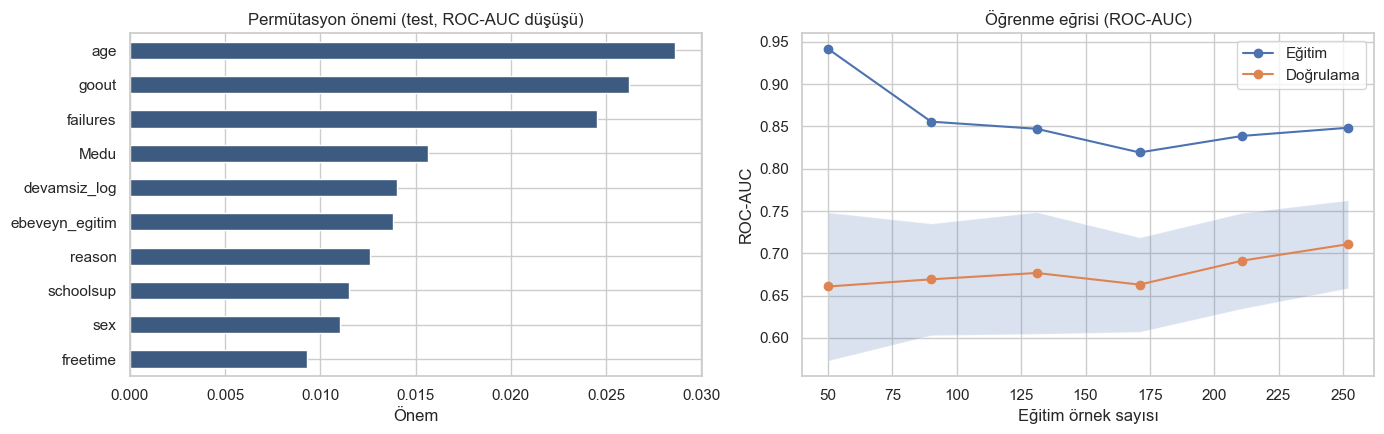

age               0.0286
goout             0.0262
failures          0.0245
Medu              0.0156
devamsiz_log      0.0140
ebeveyn_egitim    0.0138
reason            0.0126
schoolsup         0.0115
sex               0.0110
freetime          0.0093
dtype: float64
Son noktada eğitim/doğrulama AUC: 0.848 0.711


In [9]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(en_iyi, Xte, yte, n_repeats=30, random_state=42, scoring="roc_auc", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=colsA).sort_values(ascending=False).head(10)
from sklearn.model_selection import learning_curve
sizes, trs, vas = learning_curve(en_iyi, Xtr, ytr, cv=skf, scoring="roc_auc", train_sizes=np.linspace(.2, 1, 6), n_jobs=-1)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
imp[::-1].plot.barh(ax=ax[0], color="#3d5a80"); ax[0].set_title("Permütasyon önemi (test, ROC-AUC düşüşü)"); ax[0].set_xlabel("Önem")
ax[1].plot(sizes, trs.mean(1), "o-", label="Eğitim"); ax[1].plot(sizes, vas.mean(1), "o-", label="Doğrulama"); ax[1].fill_between(sizes, vas.mean(1) - vas.std(1), vas.mean(1) + vas.std(1), alpha=.2)
ax[1].set_title("Öğrenme eğrisi (ROC-AUC)"); ax[1].set_xlabel("Eğitim örnek sayısı"); ax[1].set_ylabel("ROC-AUC"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/yorumlama.png", dpi=150); plt.show()
print(imp.round(4)); print("Son noktada eğitim/doğrulama AUC:", round(trs.mean(1)[-1], 3), round(vas.mean(1)[-1], 3))
METRICS["onem"] = imp.round(4).to_dict(); METRICS["ogrenme_egrisi_son"] = [float(trs.mean(1)[-1]), float(vas.mean(1)[-1])]

## Aşama 9 — Eşik Analizi ve Hata Analizi
Okul açısından "kalacak öğrenciyi kaçırmak" pahalıdır. Eşiği düşürmek recall'ı artırır, ama destek verilecek öğrenci sayısını (maliyeti) artırır.

In [10]:
pr = sonuc[en_iyi_ad]["proba"]; rows = []
for th_ in (0.5, 0.4, 0.3, 0.25, 0.2):
    p = (pr >= th_).astype(int)
    rows.append(dict(esik=th_, recall=recall_score(yte, p), precision=precision_score(yte, p, zero_division=0), isaretlenen=int(p.sum()), toplam=len(p), kacirilan=int(((p == 0) & (yte == 1)).sum())))
esik = pd.DataFrame(rows).round(3); display(esik); METRICS["esik"] = esik.to_dict("records")
hata = Xte.assign(gercek=yte.values, olasilik=pr.round(3), tahmin=sonuc[en_iyi_ad]["pred"])
fn = hata[(hata.gercek == 1) & (hata.tahmin == 0)][["failures", "studytime", "absences", "higher", "olasilik"]].sort_values("olasilik", ascending=False)
print("Kaçırılan 'kalan' öğrenciler (yanlış negatif):", len(fn)); display(fn.head(8))
METRICS["fn_sayisi"] = len(fn); METRICS["fn_ort_devamsizlik"] = float(fn.absences.mean()) if len(fn) else None; METRICS["test_kalan_devamsizlik"] = float(hata[hata.gercek == 1].absences.mean())

,esik,recall,precision,isaretlenen,toplam,kacirilan
0,0.50,0.423,0.478,23,79,15
1,0.40,0.615,0.381,42,79,10
2,0.30,0.808,0.362,58,79,5
3,0.25,0.846,0.355,62,79,4
4,0.20,0.962,0.342,73,79,1


Kaçırılan 'kalan' öğrenciler (yanlış negatif): 15


,failures,studytime,absences,higher,olasilik
333,0,2,0,yes,0.497
355,0,2,0,yes,0.466
394,0,1,5,yes,0.423
136,0,2,0,yes,0.416
7,0,2,6,yes,0.408
67,0,4,4,yes,0.378
321,0,2,12,yes,0.367
1,0,2,4,yes,0.342


## Aşama 10 — Adalet (Fairness) Kontrolü
Cinsiyet (`sex`) model girdisinde var. Grup bazında recall farkı büyükse, aracın bir gruba daha az uyarı vermesi riski vardır.

In [11]:
g = []
for s_ in ("F", "M"):
    mk = (Xte.sex == s_).values
    g.append(dict(grup=s_, n=int(mk.sum()), kalan_orani=float(yte[mk].mean()), recall=recall_score(yte[mk], sonuc[en_iyi_ad]["pred"][mk]), precision=precision_score(yte[mk], sonuc[en_iyi_ad]["pred"][mk], zero_division=0)))
fair = pd.DataFrame(g).round(3); display(fair); METRICS["fairness"] = fair.to_dict("records")

,grup,n,kalan_orani,recall,precision
0,F,47,0.362,0.294,0.333
1,M,32,0.281,0.667,0.750


## Aşama 11 — Modeli Kaydet ve Akıllı Tahmin Aracı
Model (ön işleme dahil bütün boru hattı) `models/model.joblib` olarak kaydedilir. Komut satırı aracı `tahmin_araci.py` bu dosyayı kullanır.

In [12]:
final_model = Pipeline([("pre", make_pre(colsA)), ("m", clone(tuned[en_iyi_ad].named_steps["m"]))]).fit(X_full[colsA], y_kal)   # tüm veriyle son eğitim
joblib.dump({"model": final_model, "kolonlar": colsA, "esik": 0.4}, "models/model.joblib")
medyan = X_full[colsA].median(numeric_only=True); mod = X_full[colsA].mode().iloc[0]
def tahmin_et(**ogrenci):
    """Verilmeyen alanları veri setinin tipik değeriyle doldurur ve kalma riskini yorumlar."""
    satir = {c_: (medyan[c_] if c_ in medyan else mod[c_]) for c_ in colsA}; satir.update(ogrenci)
    satir = ozellik_ekle(pd.DataFrame([satir]).assign(G3=0, gecti=0, G1=0, G2=0))[colsA]
    risk = final_model.predict_proba(satir)[0, 1]
    seviye = "YÜKSEK risk" if risk >= .6 else "ORTA risk" if risk >= .4 else "düşük risk"
    return f"Kalma olasılığı %{risk*100:.0f} → {seviye}."
print(tahmin_et(failures=2, studytime=1, absences=14, higher="no", goout=5, Walc=4))
print(tahmin_et(failures=0, studytime=3, absences=2, higher="yes"))
print(tahmin_et(failures=1, studytime=2, absences=6, higher="yes", sex="M"))
METRICS["ornekler"] = [tahmin_et(failures=2, studytime=1, absences=14, higher="no", goout=5, Walc=4), tahmin_et(failures=0, studytime=3, absences=2, higher="yes"), tahmin_et(failures=1, studytime=2, absences=6, higher="yes", sex="M")]
json.dump(METRICS, open("metrics.json", "w"), ensure_ascii=False, indent=1)

Kalma olasılığı %93 → YÜKSEK risk.
Kalma olasılığı %53 → ORTA risk.
Kalma olasılığı %65 → YÜKSEK risk.


## Sonuç
Sonuçların yorumu `Proje_Raporu.docx` ve `Sunum.pptx` içinde. Özet: ara not bilgisi olmadan tahmin zordur; ara notlarla çok kolaylaşır. Bu fark, "erken uyarı" ile "geç uyarı" arasındaki gerçek ödünleşimi gösterir.